In [1]:
%%html
<div style="background: repeating-linear-gradient(
  90deg,
  #ffcc00,
  #ffcc00 40px,
  #cc0000 40px,
  #cc0000 80px
); padding: 30px 20px; border-radius: 15px; color: white; text-align: center;">

  <h1 style="margin: 0; font-size: 48px; text-shadow: 2px 2px 4px black;">
    📘 Barcelona Air Quality Report
  </h1>

  <p style="margin: 10px 0 0 0; font-size: 24px; font-style: italic; text-shadow: 1px 1px 2px black;">
    Date: July 2025
  </p>

  <hr style="margin: 20px auto; width: 80%; border: 1px solid white;">

  <p style="margin: 0; font-size: 18px; font-style: italic; text-shadow: 1px 1px 2px black;">
    Authors: Ana Awad, Alejandro Gutierrez, Nikoletta Solarz, Georgi Opnakov & Henning Peleikis
  </p>
</div>


<div style="
  background: linear-gradient(90deg, #fff3b0, #ffd6d6);
  padding: 12px 15px;
  margin: 25px 0;
  text-align: center;
  font-size: 18px;
  font-weight: bold;
  border-radius: 12px;
  color: #4a4a4a;
">
  Dataset: Air Quality Measurement
</div>


<div style="
  background-color: #fefae0;
  border-top: 5px solid #fac8c8;
  padding: 14px;
  margin: 30px 0;
  font-size: 18px;
  color: #333;
  font-weight: bold;
  border-radius: 10px;
  box-shadow: 0 2px 4px rgba(0,0,0,0.05);
">
Spark Session & connection with MinIO
</div>


<div style="
  background-color: #fefefe;
  border-left: 6px solid #ffb3ab;
  padding: 10px 15px;
  margin: 10px 0 20px 0;
  border-radius: 8px;
  font-size: 15px;
  color: #333;
  box-shadow: 1px 1px 4px rgba(0,0,0,0.05);
">
  💡 In this code we are starting our Spark Session and connecting with MinIO, where we have a bucket containing raw data from the <b>Barcelona Open Data</b> portal.
</div>


In [2]:
#importing everything relevant
import pandas as pd
pd.set_option('display.max_colwidth', None)
from pyspark.sql.session import SparkSession
from pyspark.sql.functions import input_file_name, col, when, trim, to_date, to_timestamp, lit, concat_ws, lpad, col, mean
from functools import reduce
import operator
from pyspark.sql import functions as F
import numpy as np
from pyspark.sql.types import IntegerType
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns


In [3]:
# we are starting the spark session
spark_session = \
  SparkSession.builder\
              .appName("Barcelona Air Quality Analysis")\
              .getOrCreate()

25/07/24 22:12:56 WARN Utils: Your hostname, osbdet resolves to a loopback address: 127.0.0.1; using 10.0.2.15 instead (on interface enp0s3)
25/07/24 22:12:56 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/07/24 22:12:57 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [4]:
import os
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.access.key", os.environ.get("MINIO_ACCESS_KEY", ""))
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.secret.key", os.environ.get("MINIO_SECRET_KEY", ""))
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.path.style.access", "true")
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem")
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.endpoint", "http://localhost:9000")

<div style="
  background-color: #fff8dc;
  border-top: 5px solid #fac8c8;
  padding: 14px;
  margin: 30px 0;
  font-size: 18px;
  color: #333;
  font-weight: bold;
  border-radius: 10px;
  box-shadow: 0 2px 4px rgba(0,0,0,0.05);
">
  🧩 Data Merging
</div>

<div style="
  background-color: #fefefe;
  border-left: 6px solid #ffcc80;
  padding: 10px 15px;
  margin: 20px 0;
  border-radius: 8px;
  font-size: 15px;
  color: #333;
  box-shadow: 1px 1px 4px rgba(0,0,0,0.05);
">
We are reading from the same MinIO bucket and filtering the files using a naming pattern to select only the ones we need. Since they share the same schema, Spark can read them as a single logical dataset. We also perform a quick visualization to check that the load was successful. We also save a version of the combined data in a bucket (bronze-bcn-airquality)
</div>


In [5]:
# Change file path to reference raw data location for air quality files pulled from Nifi, we put + to get the ones related to the monthly data
df_all = spark_session.read.options(header='True', inferSchema='True', delimiter=',')\
                                .csv("s3a://raw-bcn-airquality/raw_bcn_airquality_data_0*.csv")

# To visualize schema and make sure we got it correctly
# df_all.printSchema()

25/07/24 22:13:00 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties
25/07/24 22:13:00 WARN VersionInfoUtils: The AWS SDK for Java 1.x entered maintenance mode starting July 31, 2024 and will reach end of support on December 31, 2025. For more information, see https://aws.amazon.com/blogs/developer/the-aws-sdk-for-java-1-x-is-in-maintenance-mode-effective-july-31-2024/
You can print where on the file system the AWS SDK for Java 1.x core runtime is located by setting the AWS_JAVA_V1_PRINT_LOCATION environment variable or aws.java.v1.printLocation system property to 'true'.
This message can be disabled by setting the AWS_JAVA_V1_DISABLE_DEPRECATION_ANNOUNCEMENT environment variable or aws.java.v1.disableDeprecationAnnouncement system property to 'true'.
The AWS SDK for Java 1.x is being used here:
at java.base/java.lang.Thread.getStackTrace(Thread.java:2451)
at com.amazonaws.util.VersionInfoUtils.printDeprecationAn

In [6]:
df_all.toPandas()

25/07/24 22:13:11 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
25/07/24 22:13:11 WARN GarbageCollectionMetrics: To enable non-built-in garbage collector(s) List(G1 Concurrent GC), users should configure it(them) to spark.eventLog.gcMetrics.youngGenerationGarbageCollectors or spark.eventLog.gcMetrics.oldGenerationGarbageCollectors
                                                                                

,CODI_PROVINCIA,PROVINCIA,CODI_MUNICIPI,MUNICIPI,ESTACIO,CODI_CONTAMINANT,ANY,MES,DIA,H01,...,H20,V20,H21,V21,H22,V22,H23,V23,H24,V24
0,8,Barcelona,19,Barcelona,4,7,2024,12,1,35,...,3,V,13,V,9,V,11,V,2,V
1,8,Barcelona,19,Barcelona,4,7,2024,12,2,1,...,3,V,6,V,13,V,17,V,9,V
2,8,Barcelona,19,Barcelona,4,7,2024,12,3,8,...,4,V,14,V,9,V,5,V,2,V
3,8,Barcelona,19,Barcelona,4,7,2024,12,4,1,...,5,V,5,V,2,V,4,V,3,V
4,8,Barcelona,19,Barcelona,4,7,2024,12,5,2,...,44,V,29,V,35,V,7,V,2,V
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34139,8,Barcelona,19,Barcelona,58,14,2025,6,21,86,...,101,V,91,V,100,V,102,V,92,V
34140,8,Barcelona,19,Barcelona,58,14,2025,6,22,89,...,95,V,103,V,101,V,93,V,87,V
34141,8,Barcelona,19,Barcelona,58,14,2025,6,23,109,...,97,V,94,V,100,V,101,V,105,V
34142,8,Barcelona,19,Barcelona,58,14,2025,6,24,95,...,98,V,94,V,97,V,99,V,92,V


In [7]:
df_all.coalesce(1).write \
    .mode("overwrite") \
    .option("header", "true") \
    .csv("s3a://bronze-bcn-airquality/combined-air-quality/")

25/07/24 22:13:16 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.
25/07/24 22:13:16 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.
                                                                                

<div style="
  background-color: #fff8dc;
  border-top: 5px solid #fac8c8;
  padding: 14px;
  margin: 30px 0;
  font-size: 18px;
  color: #333;
  font-weight: bold;
  border-radius: 10px;
  box-shadow: 0 2px 4px rgba(0,0,0,0.05);
">
   Data Preparation
</div>

<div style="
  background-color: #fefefe;
  border-left: 6px solid #ffcc80;
  padding: 10px 15px;
  margin: 20px 0;
  border-radius: 8px;
  font-size: 15px;
  color: #333;
  box-shadow: 1px 1px 4px rgba(0,0,0,0.05);
">
Filter out rows with insufficient validation data.
We focus on all columns that begin with V (validation), and discard any row that doesn’t contain enough non-null values in those columns.
</div>


In [8]:
## Removing rows with less than 50% Validated data
v_cols = [f"V{str(i).zfill(2)}" for i in range(1, 25)]

# Build expression: when(col("V01") == "V", 1).otherwise(0) + ... + when(col("V24") == "V", 1).otherwise(0)
v_count_expr = reduce(
    operator.add,
    [when(col(c) == "V", 1).otherwise(0) for c in v_cols]
)

df = df_all.withColumn("v_flag_count", v_count_expr)
df = df.filter(col("v_flag_count") >= 12).drop("v_flag_count") #new df in which we drop those that don't provide enough information


<div style="
  background-color: #fefefe;
  border-left: 6px solid #ffcc80;
  padding: 10px 15px;
  margin: 20px 0;
  border-radius: 8px;
  font-size: 15px;
  color: #333;
  box-shadow: 1px 1px 4px rgba(0,0,0,0.05);
">
  Next, since we are only interested in contaminant code 8, we filter the dataset to keep only the rows where CODI_CONTAMINANT equals 8.
</div>


In [9]:
# Keep only rows where CODI_CONTAMINANT == 8 (target pollutant)

df = df.filter(
    trim(col("CODI_CONTAMINANT")).cast("int") == 8
)

<div style="
  background-color: #fefefe;
  border-left: 6px solid #ffcc80;
  padding: 10px 15px;
  margin: 20px 0;
  border-radius: 8px;
  font-size: 15px;
  color: #333;
  box-shadow: 1px 1px 4px rgba(0,0,0,0.05);
">
We drop the first four columns, as they are not relevant for our analysis.
These columns were marked as non-essential in the data dictionary, so we remove them to simplify the dataset.
</div>


In [10]:
# Drop non-relevant columns based on the data dictionary
df = df.drop('CODI_PROVINCIA', 'PROVINCIA', 'CODI_MUNICIPI','MUNICIPI')

<div style="
  background-color: #fefefe;
  border-left: 6px solid #ffcc80;
  padding: 10px 15px;
  margin: 20px 0;
  border-radius: 8px;
  font-size: 15px;
  color: #333;
  box-shadow: 1px 1px 4px rgba(0,0,0,0.05);
">
We replace the string "NA" with null values (None) across all columns.
This ensures that "NA" entries are properly recognized as missing data rather than string values.
</div>


In [11]:
# Replace "NA" strings with nulls (None) in all columns
df = df.select([
    when(col(c) == "NA", None).otherwise(col(c)).alias(c)
    for c in df.columns
])

<div style="
  background-color: #fefefe;
  border-left: 6px solid #ffcc80;
  padding: 10px 15px;
  margin: 20px 0;
  border-radius: 8px;
  font-size: 15px;
  color: #333;
  box-shadow: 1px 1px 4px rgba(0,0,0,0.05);
">
We remove the validation columns, as they have already been used to filter the data.
These columns are no longer needed in the dataset moving forward.
</div>


In [12]:
# Identify validation columns by pattern: V01 to V24
v_cols = [f"V{str(i).zfill(2)}" for i in range(1, 25)]

# Drop the validation columns (used earlier to filter rows)
df= df.drop(*v_cols)

<div style="
  background-color: #fefefe;
  border-left: 6px solid #ffcc80;
  padding: 10px 15px;
  margin: 20px 0;
  border-radius: 8px;
  font-size: 15px;
  color: #333;
  box-shadow: 1px 1px 4px rgba(0,0,0,0.05);
">
We compute the daily average from the 24 hourly measurements (H01 to H24) by summing the non-null values and dividing by the number of available (non-null) measurements.
Once the daily average is created, we drop the individual hourly columns from the dataset.
</div>


In [13]:
# Define hourly columns: H01 to H24
h_columns = [f"H{i:02d}" for i in range(1, 25)]

# Add daily average column (ignoring nulls)
df = df.withColumn(
    "daily_avg",
    F.expr(f"""
        aggregate(
            filter(array({','.join([f"`{col}`" for col in h_columns])}), x -> x is not null),
            cast(0.0 as double),
            (acc, x) -> acc + x
        ) / size(filter(array({','.join([f"`{col}`" for col in h_columns])}), x -> x is not null))
    """)
)
df_hour = df

# Drop hourly columns after averaging
df = df.drop(*h_columns)


<div style="
  background-color: #fefefe;
  border-left: 6px solid #ffcc80;
  padding: 10px 15px;
  margin: 20px 0;
  border-radius: 8px;
  font-size: 15px;
  color: #333;
  box-shadow: 1px 1px 4px rgba(0,0,0,0.05);
">
We generate a proper date column by combining ANY, MES, and DIA.
This allows us to sort or group data chronologically.
We store both a DateType (midnight) and a full TimestampType for flexibility.
</div>


In [14]:
# Combine year, month, and day columns into string: yyyy-MM-dd
df = df.withColumn(
    "date_str",
    concat_ws("-",
      col("ANY"),
      lpad(col("MES"), 2, "0"),
      lpad(col("DIA"), 2, "0")
    )
)


# create a full TimestampType column 
df = df.withColumn(
    "datetime",
    to_timestamp(
      concat_ws(" ", col("date_str"), lit("00:00:00")),
      "yyyy-MM-dd HH:mm:ss"
    )
)

df_station_visualize = df
df = df.orderBy(col("datetime").asc())
df = df.drop('date_str', 'date')

In [15]:
#sacing in  bucket
df.coalesce(1).write \
    .mode("overwrite") \
    .option("header", "true") \
    .csv("s3a://gold-bcn-airquality/air-quality/")

25/07/24 22:13:25 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.
25/07/24 22:13:26 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.
                                                                                

<div style="
  background: linear-gradient(90deg, #fff3b0, #ffd6d6);
  padding: 12px 15px;
  margin: 25px 0;
  text-align: center;
  font-size: 18px;
  font-weight: bold;
  border-radius: 12px;
  color: #4a4a4a;
">
  Dataset: Station  Information
</div>

In [16]:
# Get station data
df_station = spark_session.read.option("header", "true").csv("s3a://raw-bcn-airquality/raw_data_air_quality_estacion.csv")

# Only keep needed columns
columns_to_keep = ["Estacio", "nom_cabina", "Longitud", "Latitud", "Codi_districte"]

df_station_cleaned = df_station.select(*columns_to_keep)

#saving this information as bronze bucket
df_station_cleaned.coalesce(1).write \
    .mode("overwrite") \
    .option("header", "true") \
    .csv("s3a://bronze-bcn-airquality/clean-station-data/")

25/07/24 22:13:27 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.
25/07/24 22:13:27 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.


In [17]:
df_with_station = df_hour.join(df_station_cleaned, on= "Estacio")
value_cols = [c for c in df_with_station.columns if c.startswith("H")]

for c in value_cols:
    df_with_station = df_with_station.withColumn(c, col(c).cast(IntegerType()))

df_with_station_monthly_avg = df_with_station.groupby(["ESTACIO", "ANY", "MES"]).mean().sort(["ESTACIO", "ANY", "MES"])
df_monthly_avg = df_with_station.where(df_with_station.ANY == 2024).groupby(["ANY", "MES"]).mean().sort(["ANY", "MES"])

value_cols_avg = [("avg("+c+")") for c in value_cols]
value_cols_avg.insert(0,"ANY")
value_cols_avg.insert(1,"MES")

df_monthly_avg = df_monthly_avg.select(value_cols_avg)
df =df_monthly_avg
pd_monthly = df_monthly_avg.toPandas()

#saving as silver bucket this df
df.coalesce(1).write \
    .mode("overwrite") \
    .option("header", "true") \
    .csv("s3a://silver-bcn-airquality/station_monthly_avg")

df_with_station_yearly_avg = df_with_station.where(df_with_station.ANY == 2024).groupby(["ESTACIO", "ANY"]).mean().sort(["ESTACIO", "ANY"])

df =df_with_station_yearly_avg
#saving as bucket this df
df.coalesce(1).write \
    .mode("overwrite") \
    .option("header", "true") \
    .csv("s3a://gold-bcn-airquality/station_monthly_avg-year/")

25/07/24 22:13:35 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.
25/07/24 22:13:35 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.
25/07/24 22:13:39 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.
25/07/24 22:13:39 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.


<div style="
  background: linear-gradient(90deg, #fff3b0, #ffd6d6);
  padding: 12px 15px;
  margin: 25px 0;
  text-align: center;
  font-size: 18px;
  font-weight: bold;
  border-radius: 12px;
  color: #4a4a4a;
">
  Dataset: Demographics  Information
</div>

In [18]:
#age data spark session
df_demographics = spark_session.read.option("header", "true").json("s3a://raw-bcn-airquality/raw_bcn_population_data_0*.json")

#selecting columns we want to keep
columns_to_keep = ["Data_Referencia", "Codi_Districte", "Valor", "EDAT_1"]
df_demographics_cleaned = df_demographics.select(*columns_to_keep)

df_demographics_cleaned.coalesce(1).write \
    .mode("overwrite") \
    .option("header", "true") \
    .csv("s3a://bronze-bcn-airquality/clean-age-data/")



25/07/24 22:13:41 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.
25/07/24 22:13:41 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.
                                                                                

In [19]:
#defining which buckets we want
df_demographics_trim_classified = df_demographics_cleaned \
    .withColumn(
        "Age_Bucket",
        when(col("EDAT_1").between(0, 4), "0 - 4 age group")
        .when(col("EDAT_1").between(5, 14), "5 - 14 age group")
        .when(col("EDAT_1").between(15, 34), "15 - 34 age group")
        .when(col("EDAT_1").between(35, 64), "35 - 64 age group")
        .when(col("EDAT_1") >= 65, "65+ age group")
        .otherwise("Unknown")
    ) \
    .withColumn(
        "Vulnerable",
        when((col("EDAT_1").between(0, 4)) | (col("EDAT_1") >= 65), "Y").otherwise("N")
    )

#preparing for later visualization
pd_demographics_heat = df_demographics_trim_classified.toPandas()

#selecting districts we know we have data for the air quality
selected_districts = [10, 3, 5, 6, 1, 7, 4]
df_demo_filtered = df_demographics_trim_classified.filter(
    col("Codi_Districte").isin(selected_districts)
)

#saving as silver bucket this df
df_demo_filtered.coalesce(1).write \
    .mode("overwrite") \
    .option("header", "true") \
    .csv("s3a://silver-bcn-airquality/age_data/")

pd_demo_filtered = df_demo_filtered.toPandas()
pd_demo_filtered = pd_demo_filtered.copy()
pd_demo_filtered["Valor"] = (
    pd_demo_filtered["Valor"]
    .astype(str)
    .str.replace(",", "")
    .str.strip()
)

pd_demo_filtered["Valor"] = pd.to_numeric(
    pd_demo_filtered["Valor"], errors="coerce"
)

# Drop invalid rows
pd_demo_filtered = pd_demo_filtered.dropna(subset=["Valor"])


#saving as silver bucket this df
df_demo_filtered.coalesce(1).write \
    .mode("overwrite") \
    .option("header", "true") \
    .csv("s3a://gold-bcn-airquality/age_data/")

25/07/24 22:13:48 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.
25/07/24 22:13:49 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.
25/07/24 22:13:54 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.
25/07/24 22:13:54 WARN AbstractS3ACommitterFactory: Using standard FileOutputCommitter to commit work. This is slow and potentially unsafe.
                                                                                

<div style="
  background: linear-gradient(90deg, #fff3b0, #ffd6d6);
  padding: 12px 15px;
  margin: 25px 0;
  text-align: center;
  font-size: 18px;
  font-weight: bold;
  border-radius: 12px;
  color: #4a4a4a;
">
  VISUALIZATION & RESULTS
</div>

/tmp/ipykernel_9467/2247842255.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap('tab20', len(months_sorted))


<Figure size 1400x600 with 0 Axes>

Text(0.5, 1.0, 'Hourly Air Quality Averages per Month')

Text(0.5, 0, 'Hour of Day')

Text(0, 0.5, 'Average Value')

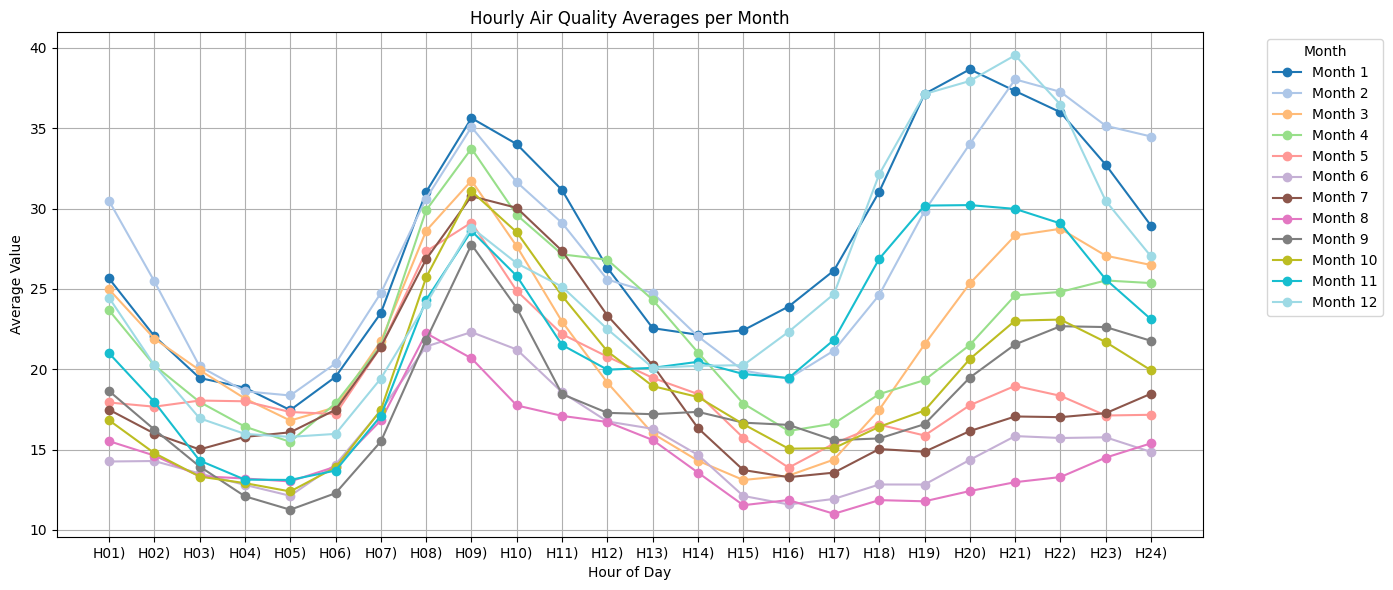

In [20]:
# Extract hour columns
hour_columns = [col for col in pd_monthly.columns if col.startswith('avg(H')]
hour_labels = [col[4:] for col in hour_columns]

# Prepare months
months_sorted = sorted(pd_monthly['MES'].unique())
colors = cm.get_cmap('tab20', len(months_sorted))

# Plot
plt.figure(figsize=(14, 6))

for i, month in enumerate(months_sorted):
    row = pd_monthly[pd_monthly['MES'] == month].iloc[0]
    values = [row[col] for col in hour_columns]
    plt.plot(hour_labels, values, marker='o', label=f"Month {int(month)}", color=colors(i))

# Formatting
plt.title('Hourly Air Quality Averages per Month')
plt.xlabel('Hour of Day')
plt.ylabel('Average Value')
plt.legend(title='Month', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

<Figure size 1400x600 with 0 Axes>

Text(0.5, 1.0, 'Hourly Air Quality Averages per Month')

Text(0.5, 0, 'Hour of Day')

Text(0, 0.5, 'Average Value')

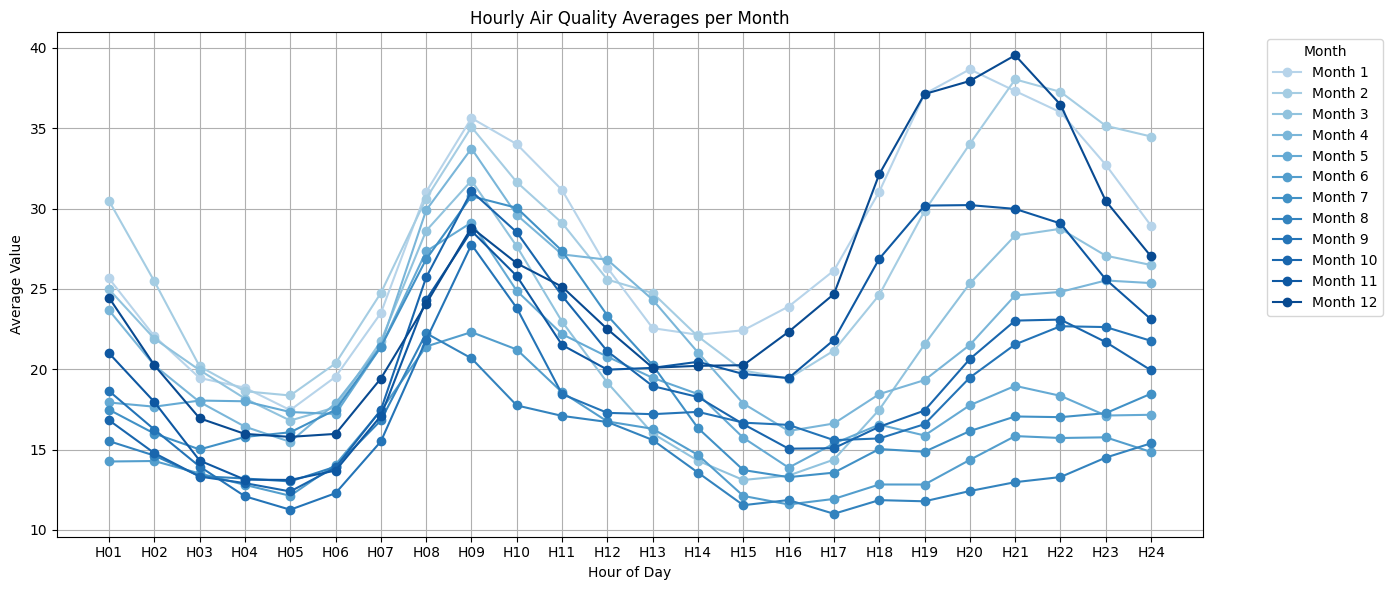

In [21]:

# Extract hour columns
hour_columns = [col for col in pd_monthly.columns if col.startswith('avg(H')]
hour_labels = [col[4:-1] for col in hour_columns]  # Extract 01, 02, ..., 24

# Prepare color map: 12 shades from light to dark
months_sorted = sorted(pd_monthly['MES'].unique())
colors = cm.Blues(np.linspace(0.3, 0.9, len(months_sorted)))  # lighter to darker


# Set up the plot
plt.figure(figsize=(14, 6))

# Plot one line per month with gradient color
for i, month in enumerate(months_sorted):
    row = pd_monthly[pd_monthly['MES'] == month].iloc[0]
    values = [row[col] for col in hour_columns]
    plt.plot(hour_labels, values, marker='o', label=f"Month {int(month)}", color=colors[i])

# Formatting
plt.title('Hourly Air Quality Averages per Month')
plt.xlabel('Hour of Day')
plt.ylabel('Average Value')
plt.legend(title='Month', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()


<Figure size 1600x800 with 0 Axes>

<Axes: ylabel='ESTACIO'>

Text(0.5, 1.0, 'Hourly Air Quality Heatmap by Station')

Text(0.5, 58.7222222222222, 'Hour of Day')

Text(170.72222222222223, 0.5, 'Station ID')

([<matplotlib.axis.XTick at 0x7faa673cf650>,
 [Text(0.5, 0, 'H01'),
  Text(1.5, 0, 'H02'),
  Text(2.5, 0, 'H03'),
  Text(3.5, 0, 'H04'),
  Text(4.5, 0, 'H05'),
  Text(5.5, 0, 'H06'),
  Text(6.5, 0, 'H07'),
  Text(7.5, 0, 'H08'),
  Text(8.5, 0, 'H09'),
  Text(9.5, 0, 'H10'),
  Text(10.5, 0, 'H11'),
  Text(11.5, 0, 'H12'),
  Text(12.5, 0, 'H13'),
  Text(13.5, 0, 'H14'),
  Text(14.5, 0, 'H15'),
  Text(15.5, 0, 'H16'),
  Text(16.5, 0, 'H17'),
  Text(17.5, 0, 'H18'),
  Text(18.5, 0, 'H19'),
  Text(19.5, 0, 'H20'),
  Text(20.5, 0, 'H21'),
  Text(21.5, 0, 'H22'),
  Text(22.5, 0, 'H23'),
  Text(23.5, 0, 'H24')])

(array([0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5]),
 [Text(0, 0.5, '4'),
  Text(0, 1.5, '42'),
  Text(0, 2.5, '43'),
  Text(0, 3.5, '44'),
  Text(0, 4.5, '50'),
  Text(0, 5.5, '54'),
  Text(0, 6.5, '57'),
  Text(0, 7.5, '58')])

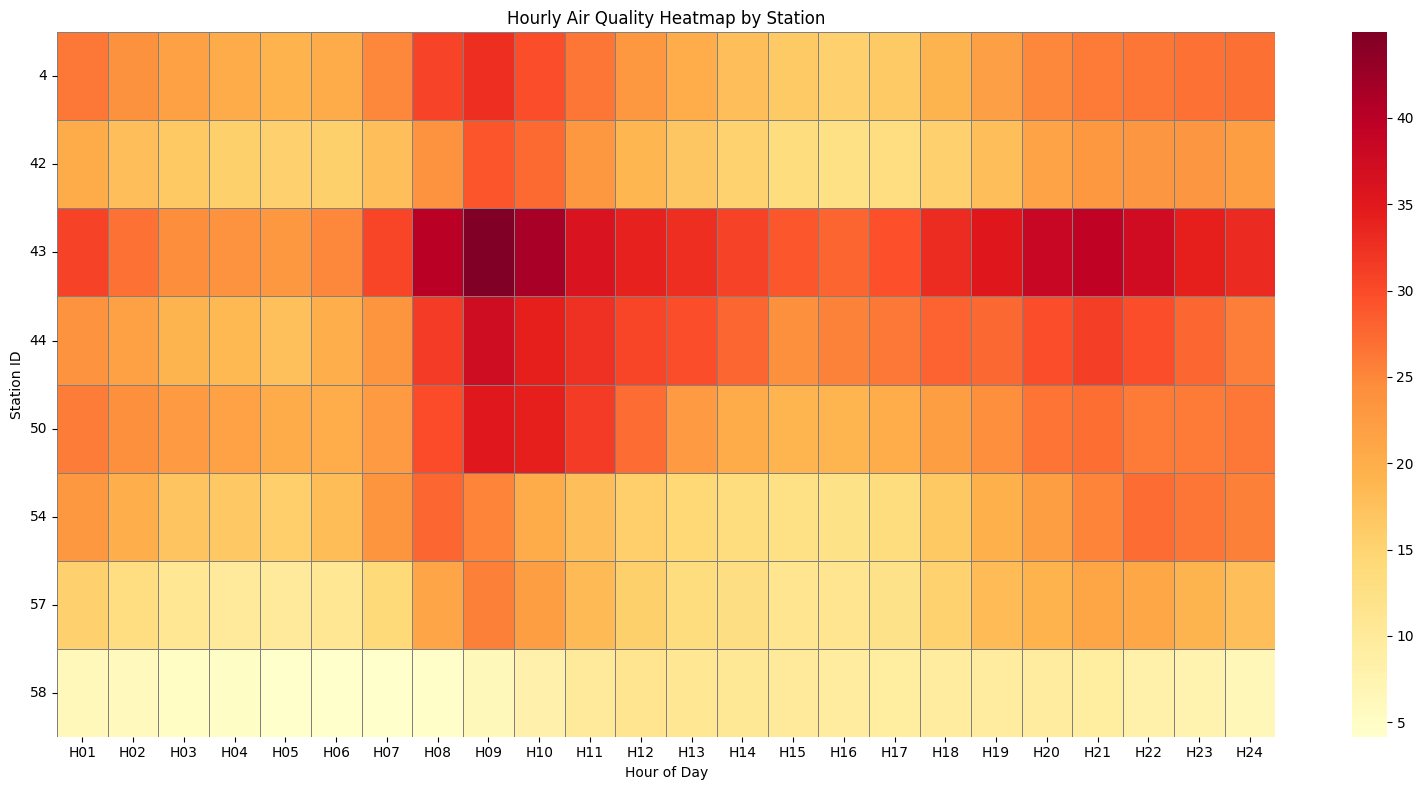

In [22]:



pd_yearly = df_with_station_yearly_avg.toPandas()

# 1. Prepare the data
# Extract only the hour columns (those that start with 'avg(H')
hour_cols = [("avg("+c+")") for c in value_cols]
heatmap_data = pd_yearly[hour_columns]  # just the numeric values

# Use ESTACIO as index
heatmap_data.index = pd_yearly['ESTACIO']
pd_yearly = df_with_station_yearly_avg.toPandas()
# 2. Create the heatmap
plt.figure(figsize=(16, 8))
sns.heatmap(heatmap_data, cmap="YlOrRd", linewidths=0.5, linecolor='gray')

# 3. Formatting
plt.title("Hourly Air Quality Heatmap by Station")
plt.xlabel("Hour of Day")
plt.ylabel("Station ID")
plt.xticks(ticks=[i + 0.5 for i in range(len(hour_columns))], labels=[h[4:-1] for h in hour_columns], rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

<Figure size 1200x800 with 0 Axes>

<Axes: xlabel='Age_Bucket', ylabel='Codi_Districte'>

Text(0.5, 1.0, 'Population by Age Group (Filtered Districts)')

Text(0.5, 58.7222222222222, 'Age Group')

Text(120.72222222222221, 0.5, 'District Code')

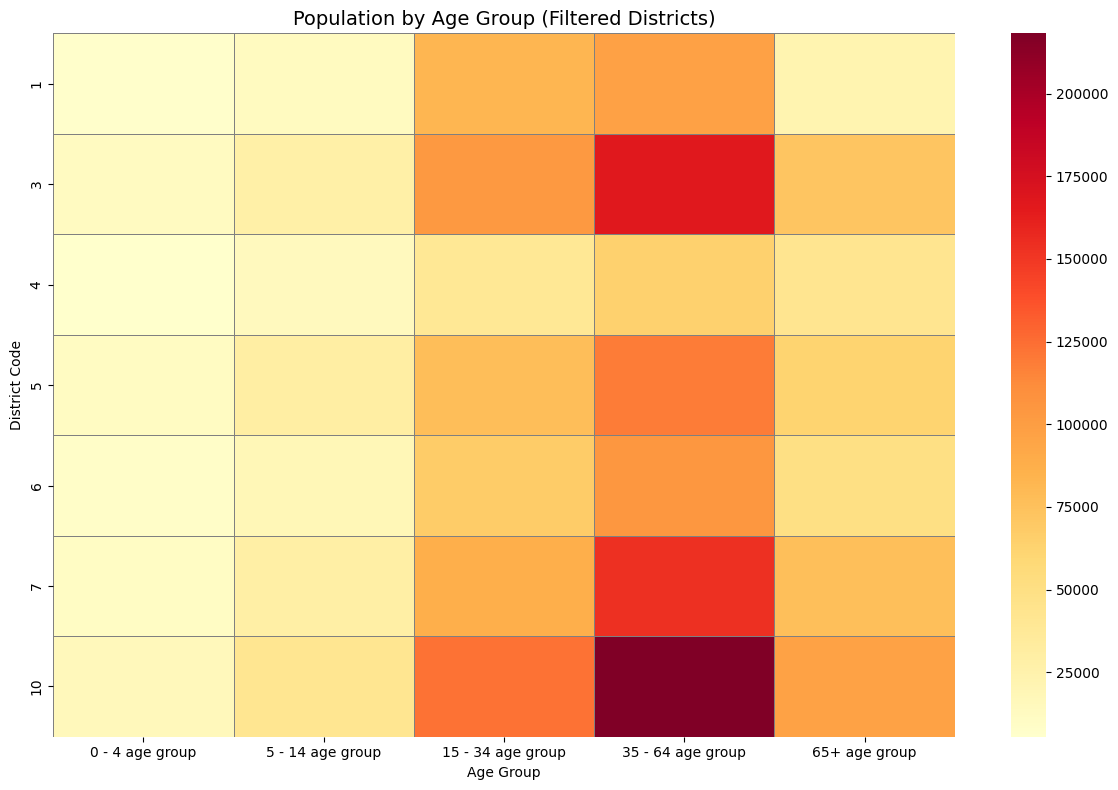

In [23]:
# Pivot table
heatmap_data = pd_demo_filtered.pivot_table(
    index="Codi_Districte",
    columns="Age_Bucket",
    values="Valor",
    aggfunc="sum",
    fill_value=0
)


heatmap_data.columns = (
    heatmap_data.columns.str.replace("–", "-", regex=False).str.strip()
)

# Define desired column order
age_order = [
    "0 - 4 age group",
    "5 - 14 age group",
    "15 - 34 age group",
    "35 - 64 age group",
    "65+ age group"
]

# Reorder columns based on age_order
heatmap_data = heatmap_data[age_order]

# Plot heatmap
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))
sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    annot=False,
    fmt=".0f",
    linewidths=0.5,
    linecolor="gray"
)

plt.title("Population by Age Group (Filtered Districts)", fontsize=14)
plt.xlabel("Age Group")
plt.ylabel("District Code")
plt.tight_layout()
plt.show()

<Figure size 1200x800 with 0 Axes>

<Axes: xlabel='Age_Bucket', ylabel='Codi_Districte'>

Text(0.5, 1.0, 'Age Group Composition per District (%)')

Text(0.5, 58.7222222222222, 'Age Group')

Text(120.72222222222221, 0.5, 'District Code')

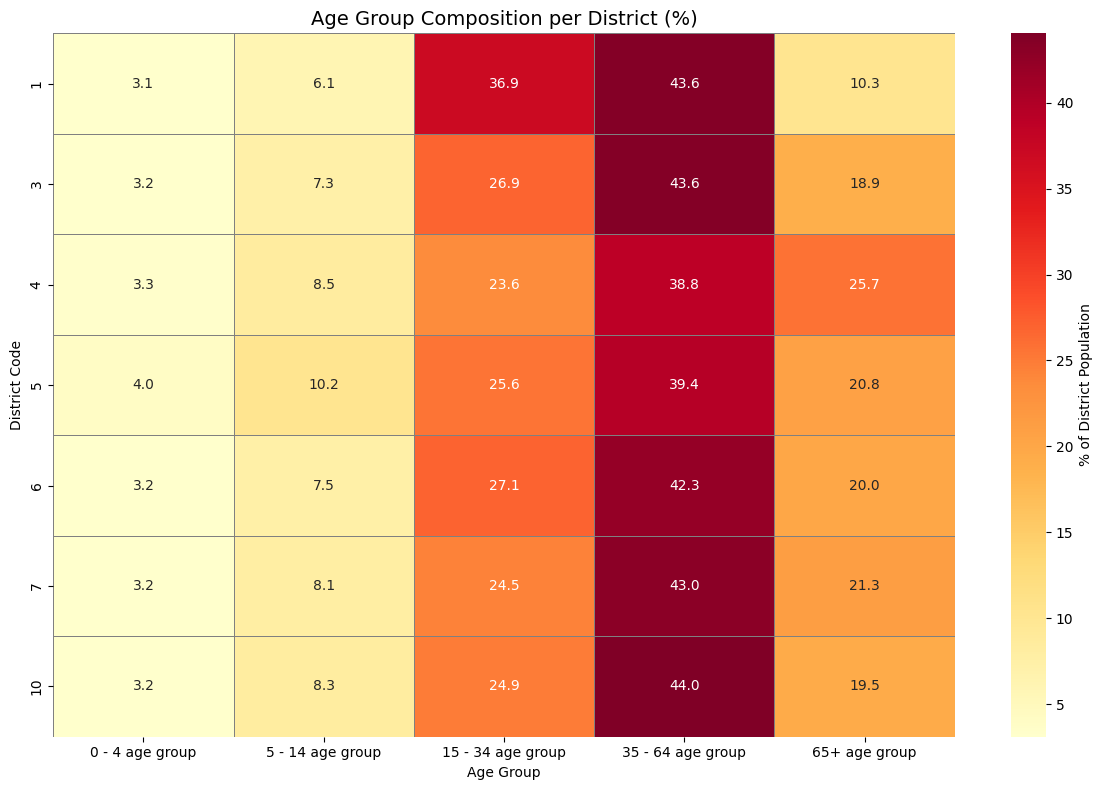

In [24]:
# Pivot as before
heatmap_data = pd_demo_filtered.pivot_table(
    index="Codi_Districte",
    columns="Age_Bucket",
    values="Valor",
    aggfunc="sum",
    fill_value=0
)

heatmap_percent = heatmap_data.div(heatmap_data.sum(axis=1), axis=0) * 100


heatmap_percent.columns = heatmap_percent.columns.str.replace("–", "-", regex=False).str.strip()

# Reorder columns
age_order = [
    "0 - 4 age group",
    "5 - 14 age group",
    "15 - 34 age group",
    "35 - 64 age group",
    "65+ age group"
]
heatmap_percent = heatmap_percent[age_order]
plt.figure(figsize=(12, 8))
sns.heatmap(
    heatmap_percent,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    linecolor="gray",
    cbar_kws={"label": "% of District Population"}
)

plt.title("Age Group Composition per District (%)", fontsize=14)
plt.xlabel("Age Group")
plt.ylabel("District Code")
plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

Text(0.5, 1.0, 'Average Air Quality per Station (Monthly Trend)')

Text(0.5, 0, 'Month')

Text(0, 0.5, 'Average Pollution')

([<matplotlib.axis.XTick at 0x7faa5f88d990>,
 [Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5'),
  Text(6, 0, '6'),
  Text(7, 0, '7'),
  Text(8, 0, '8'),
  Text(9, 0, '9'),
  Text(10, 0, '10'),
  Text(11, 0, '11'),
  Text(12, 0, '12')])

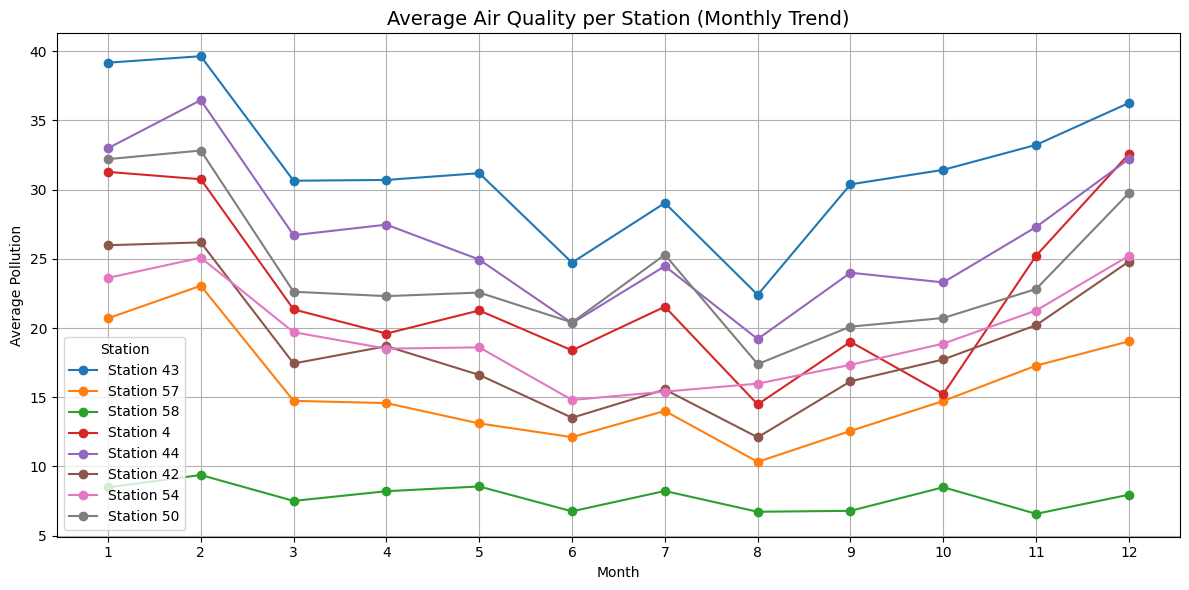

In [25]:
from pyspark.sql.functions import mean
import matplotlib.pyplot as plt
# Step 1: Group and aggregate monthly average pollution
df_air_avg = df_station_visualize.groupBy("ESTACIO", "MES").agg(
    mean("daily_avg").alias("monthly_avg_pollution")
)

# Step 2: Convert to Pandas
pd_air = df_air_avg.toPandas()

# Step 3: Plot
plt.figure(figsize=(12, 6))

for station_id in pd_air["ESTACIO"].unique():
    station_data = pd_air[pd_air["ESTACIO"] == station_id].sort_values("MES")
    plt.plot(
        station_data["MES"],
        station_data["monthly_avg_pollution"],
        marker="o",
        label=f"Station {station_id}"
    )

plt.title("Average Air Quality per Station (Monthly Trend)", fontsize=14)
plt.xlabel("Month")
plt.ylabel("Average Pollution")
plt.legend(title="Station")
plt.grid(True)
plt.xticks(range(1, 13))  # months 1–12
plt.tight_layout()
plt.show()

In [ ]:
import os
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("MinIO Committer Fix") \
    .config("spark.hadoop.fs.s3a.endpoint", "http://localhost:9000") \
    .config("spark.hadoop.fs.s3a.access.key", os.environ.get("MINIO_ACCESS_KEY", "")) \
    .config("spark.hadoop.fs.s3a.secret.key", os.environ.get("MINIO_SECRET_KEY", "")) \
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
    .config("spark.hadoop.fs.s3a.path.style.access", "true") \
    .config("spark.hadoop.mapreduce.fileoutputcommitter.algorithm.version", "2") \
    .config("spark.hadoop.fs.s3a.committer.name", "directory") \
    .config("spark.hadoop.fs.s3a.committer.staging.conflict-mode", "replace") \
    .config("spark.hadoop.fs.s3a.committer.magic.enabled", "false") \
    .getOrCreate()

## SAVING THE COMBINED DATAFILE in MinIO